# The Synthetic Crowd: Integration All the Way Down

*Companion notebook for "The Synthetic Crowd: Inferring Consumers to Understand Markets with PyMC-Marketing", PyCon Ireland 2026. Nathaniel Forde.*

How much would sales of one cereal fall if a competitor cut its price by 10%? Answering that needs a demand model, and the Berry–Levinsohn–Pakes (BLP) model is the workhorse. At its heart is an integral: a market share is the average choice of a population of consumers whose tastes we never observe.

This notebook builds intuition for that integral one layer at a time, because BLP is really **three integrals nested inside one another**:

1. **The logit** is an integral over idiosyncratic Gumbel shocks, and it happens to have a closed form.
2. **The market share** is an integral of that logit over a crowd of heterogeneous tastes. There is no closed form, so we approximate it with a fixed population of *synthetic consumers* (Halton draws).
3. **Every elasticity and counterfactual** is an integral over the posterior: we don't know the crowd's composition, so we average over every crowd consistent with the data.

We climb the ladder with plain numpy, fit a Bayesian BLP from scratch in PyMC, and then use the `BayesianBLP` class in PyMC-Marketing on synthetic data with endogenous prices and on Nevo's (2000) cereal panel.

In [1]:
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy.stats import norm, qmc

import pymc_marketing
from pymc_marketing.customer_choice import BayesianBLP, generate_blp_panel

warnings.filterwarnings("ignore")

SEED = sum(map(ord, "synthetic-crowd"))
rng = np.random.default_rng(SEED)
FIT_KWARGS = {"nuts_sampler": "nutpie", "draws": 1000, "tune": 1000, "chains": 4,
              "target_accept": 0.95, "random_seed": SEED, "progressbar": False}

IMAGES = "../images"
TEAL, CORAL, DARK, GREY, BLUE, GOLD = "#1a9988", "#e07050", "#2a3439", "#888888", "#3B9DDD", "#d4a017"
PRODUCT_COLOURS = [TEAL, BLUE, CORAL]
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": DARK,
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK, "text.color": DARK,
    "font.size": 12, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})
print(f"PyMC {pm.__version__} | PyMC-Marketing {pymc_marketing.__version__} | ArviZ {az.__version__}")

/Users/nathanielforde/Documents/Github/bayesian_causal_inference/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyMC 6.3.2 | PyMC-Marketing 1.2.0 | ArviZ 1.3.0


In [2]:
def halton_normal(n, d, seed):
    # Owen-scrambled Halton points mapped to N(0, 1): a fixed, evenly spread crowd.
    u = qmc.Halton(d=d, scramble=True, seed=seed).random(n)
    return norm.ppf(np.clip(u, 1e-12, 1 - 1e-12))


def logit_shares(delta):
    # Choice probabilities with an outside good (utility 0) in the last slot.
    # delta has inside goods on the last axis.
    u = np.concatenate([delta, np.zeros(delta.shape[:-1] + (1,))], axis=-1)
    u = u - u.max(axis=-1, keepdims=True)
    e = np.exp(u)
    return e / e.sum(axis=-1, keepdims=True)

## Layer 0: integration is averaging

Every integral in this notebook is an expectation, and every expectation can be approximated by an average:

$$\mathbb{E}[f(\nu)] = \int f(\nu)\, dF(\nu) \approx \frac{1}{R} \sum_{r=1}^{R} f(\nu_r)$$

The only question is *which* points $\nu_r$ to average over. Independent random draws (Monte Carlo) clump and leave gaps. Low-discrepancy sequences such as scrambled Halton points spread out deliberately, so the same number of points covers the space more evenly.

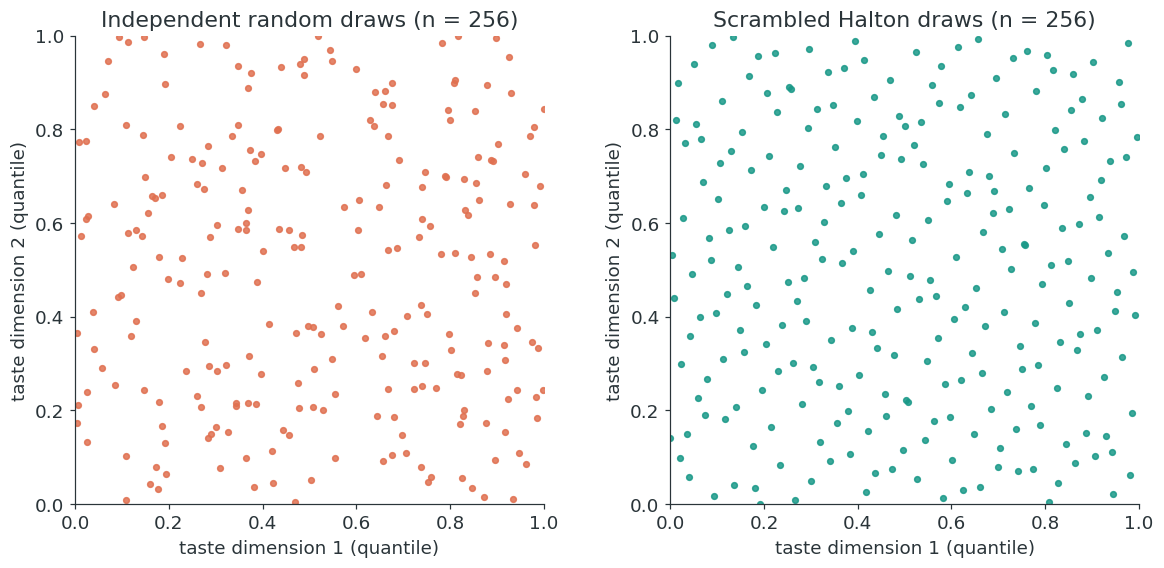

In [3]:
n_show = 256
u_random = rng.uniform(size=(n_show, 2))
u_halton = qmc.Halton(d=2, scramble=True, seed=SEED).random(n_show)

fig, axs = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, pts, title, colour in zip(
    axs, [u_random, u_halton], ["Independent random draws", "Scrambled Halton draws"], [CORAL, TEAL]
):
    ax.scatter(pts[:, 0], pts[:, 1], s=14, color=colour, alpha=0.85)
    ax.set_title(f"{title} (n = {n_show})")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xlabel("taste dimension 1 (quantile)"); ax.set_ylabel("taste dimension 2 (quantile)")
fig.tight_layout()
fig.savefig(f"{IMAGES}/halton_vs_random.png", dpi=150, bbox_inches="tight")

To see why spreading out matters, take an integral we will meet again: the market share of one product when consumers differ on **three** taste dimensions (price, and two product characteristics). The integrand is a mixed-logit share. We compute an accurate reference with a very large Halton crowd, then measure the error of smaller crowds built from random draws and from Halton draws.

In [4]:
# A three-product market; consumers differ in their taste for price and two characteristics.
price = np.array([1.0, 2.0, 3.0])
x = np.array([[0.2, 1.0], [0.8, 0.0], [1.5, 1.2]])
alpha, beta = -1.5, np.array([1.0, 0.8])
sigma = np.array([0.8, 0.6, 0.6])  # heterogeneity on price, x_0, x_1
covariates = np.column_stack([price, x])  # (J, 3)


def crowd_share(nu):
    # Market share of product 0, averaged over a crowd nu of shape (R, 3).
    delta = alpha * price + x @ beta  # mean utility (J,)
    mu = (nu * sigma) @ covariates.T  # each consumer's deviation (R, J)
    return logit_shares(delta[None, :] + mu)[:, 0].mean()


reference = crowd_share(halton_normal(2**20, 3, seed=1))
crowd_sizes = 2 ** np.arange(4, 14)
n_rep = 40
rmse = {"random": [], "halton": []}
for R in crowd_sizes:
    err_random = [crowd_share(rng.standard_normal((R, 3))) - reference for _ in range(n_rep)]
    err_halton = [crowd_share(halton_normal(R, 3, seed=s)) - reference for s in range(n_rep)]
    rmse["random"].append(np.sqrt(np.mean(np.square(err_random))))
    rmse["halton"].append(np.sqrt(np.mean(np.square(err_halton))))
rmse = pd.DataFrame(rmse, index=crowd_sizes)
rmse["ratio"] = rmse["random"] / rmse["halton"]
print(f"Reference share of product 0: {reference:.4f}")
rmse.round(5)

Reference share of product 0: 0.2683


,random,halton,ratio
16,0.03522,0.01130,3.11778
32,0.01894,0.00728,2.60021
64,0.01297,0.00374,3.46913
128,0.01045,0.00174,5.99581
256,0.00599,0.00098,6.09704
512,0.00519,0.00052,10.00412
1024,0.00423,0.00027,15.91274
2048,0.00314,0.00014,22.99041
4096,0.00206,0.00008,25.04921
8192,0.00142,0.00004,33.18589


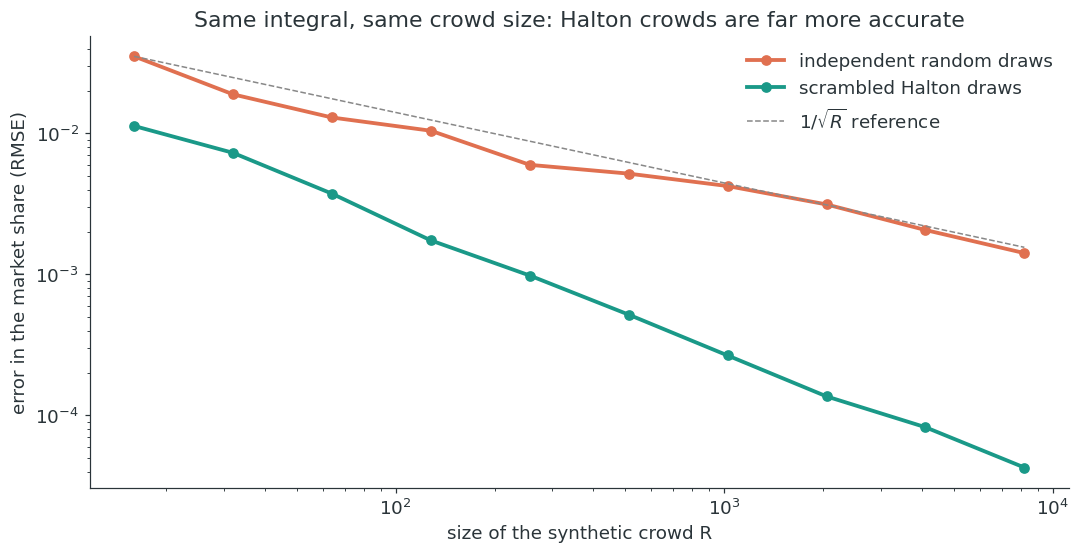

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.loglog(crowd_sizes, rmse["random"], "o-", color=CORAL, lw=2.5, label="independent random draws")
ax.loglog(crowd_sizes, rmse["halton"], "o-", color=TEAL, lw=2.5, label="scrambled Halton draws")
ax.loglog(crowd_sizes, rmse["random"].iloc[0] * np.sqrt(crowd_sizes[0] / crowd_sizes), "--",
          color=GREY, lw=1, label=r"$1/\sqrt{R}$ reference")
ax.set_xlabel("size of the synthetic crowd R")
ax.set_ylabel("error in the market share (RMSE)")
ax.set_title("Same integral, same crowd size: Halton crowds are far more accurate")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{IMAGES}/integration_convergence.png", dpi=150, bbox_inches="tight")

## Layer 1: the logit is already an integral

Before heterogeneity enters at all, the logit formula is itself the solution of an integral. Suppose each consumer $i$ gets utility $\delta_j + \varepsilon_{ij}$ from product $j$, with $\varepsilon_{ij}$ an idiosyncratic Gumbel shock, and buys whatever gives the most utility. The share of product $j$ is the probability that $j$ wins:

$$s_j = \int \mathbb{1}\Big[\delta_j + \varepsilon_{j} > \delta_k + \varepsilon_{k} \;\; \forall k \neq j\Big] \, dF(\varepsilon) = \frac{e^{\delta_j}}{1 + \sum_k e^{\delta_k}}$$

McFadden's (1974) insight is that for Gumbel shocks this integral has a closed form. We can check it the long way: simulate consumers and count choices.

closed form : [0.455 0.276 0.102 0.167]
simulated   : [0.454 0.277 0.1   0.17 ]


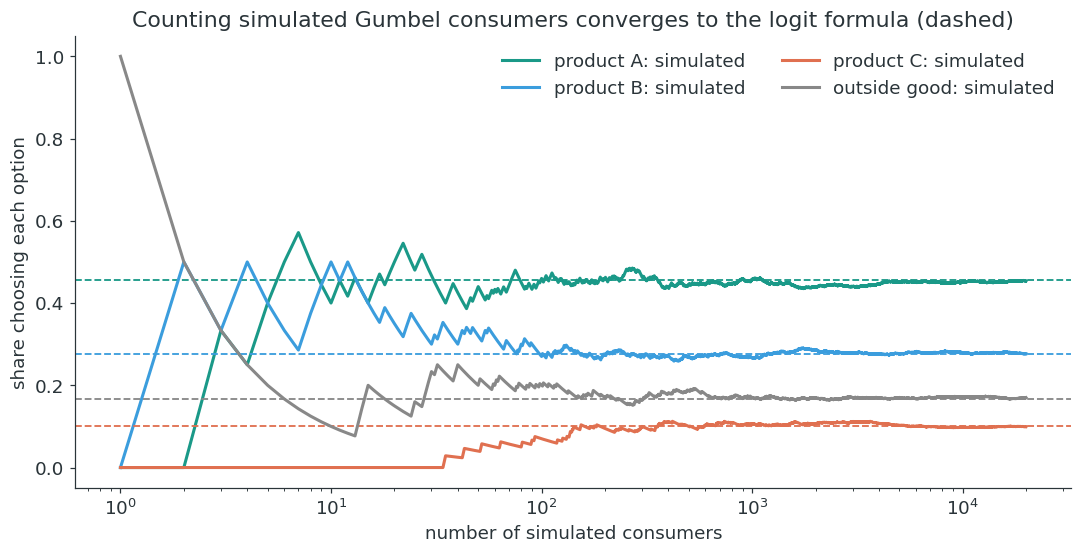

In [6]:
delta_demo = np.array([1.0, 0.5, -0.5])  # mean utilities of three products
closed_form = logit_shares(delta_demo)  # last entry is the outside good
n_consumers = 20_000
eps = rng.gumbel(size=(n_consumers, 4))
utility = np.concatenate([delta_demo, [0.0]])[None, :] + eps
choices = utility.argmax(axis=1)
running = np.stack([np.cumsum(choices == j) / np.arange(1, n_consumers + 1) for j in range(4)], axis=1)
print("closed form :", closed_form.round(3))
print("simulated   :", running[-1].round(3))

labels = ["product A", "product B", "product C", "outside good"]
colours = PRODUCT_COLOURS + [GREY]
fig, ax = plt.subplots(figsize=(10, 5.2))
n_axis = np.arange(1, n_consumers + 1)
for j in range(4):
    ax.plot(n_axis, running[:, j], color=colours[j], lw=2, label=f"{labels[j]}: simulated")
    ax.axhline(closed_form[j], color=colours[j], lw=1.2, ls="--")
ax.set_xscale("log")
ax.set_xlabel("number of simulated consumers")
ax.set_ylabel("share choosing each option")
ax.set_title("Counting simulated Gumbel consumers converges to the logit formula (dashed)")
ax.legend(frameon=False, ncol=2, loc="upper right")
fig.tight_layout()
fig.savefig(f"{IMAGES}/gumbel_to_logit.png", dpi=150, bbox_inches="tight")

## Layer 2: the synthetic crowd

The plain logit gives every consumer the *same* price sensitivity $\alpha$. Real consumers differ. BLP lets the price coefficient vary across people, $\alpha_i = \alpha + \sigma \nu_i$ with $\nu_i \sim N(0, 1)$, so a market share is an integral of the logit over the distribution of tastes:

$$s_j = \int \frac{e^{\delta_j + \sigma \nu\, p_j}}{1 + \sum_k e^{\delta_k + \sigma \nu\, p_k}} \, dF(\nu)$$

That integral has no closed form. We approximate it with a fixed population of synthetic consumers: one Halton draw per person. Each synthetic consumer has their own choice probabilities, and the market share is the crowd's average.

Below, a three-product market: a budget, a mid-range and a premium product. Consumers are sorted from most price-sensitive (left) to least (right).

crowd average     : [0.093 0.116 0.217 0.574]
average consumer  : [0.131 0.131 0.088 0.65 ]


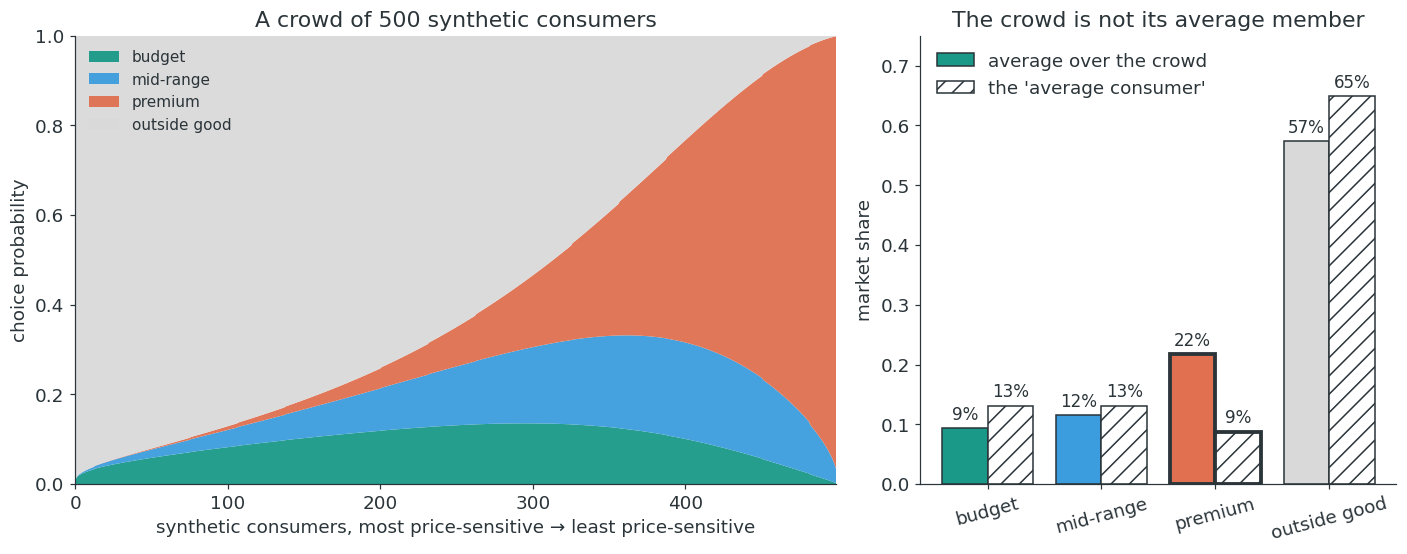

In [7]:
price_m = np.array([1.0, 2.0, 3.5])  # budget, mid, premium
quality = np.array([0.0, 1.6, 3.6])  # non-price appeal of each product
alpha_m, sigma_m = -1.6, 0.9
R_crowd = 500
nu = np.sort(halton_normal(R_crowd, 1, seed=SEED)[:, 0])
delta_m = alpha_m * price_m + quality


def crowd_probs(delta, sigma, nu, price):
    # Choice probabilities of every synthetic consumer: (R, J + 1).
    return logit_shares(delta[None, :] + sigma * nu[:, None] * price[None, :])


probs = crowd_probs(delta_m, sigma_m, nu, price_m)
crowd_avg = probs.mean(axis=0)
average_consumer = logit_shares(delta_m)
print("crowd average     :", crowd_avg.round(3))
print("average consumer  :", average_consumer.round(3))

names = ["budget", "mid-range", "premium", "outside good"]
colours = PRODUCT_COLOURS + ["#d9d9d9"]
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axs[0]
ax.stackplot(np.arange(R_crowd), probs.T, colors=colours, labels=names, alpha=0.95)
ax.set_xlim(0, R_crowd - 1); ax.set_ylim(0, 1)
ax.set_xlabel("synthetic consumers, most price-sensitive → least price-sensitive")
ax.set_ylabel("choice probability")
ax.set_title(f"A crowd of {R_crowd} synthetic consumers")
ax.legend(frameon=False, loc="upper left", fontsize=10)

ax = axs[1]
pos = np.arange(4)
bars_crowd = ax.bar(pos - 0.2, crowd_avg, width=0.4, color=colours, edgecolor=DARK,
                    label="average over the crowd")
bars_avg = ax.bar(pos + 0.2, average_consumer, width=0.4, color="white", edgecolor=DARK, hatch="//",
                  label="the 'average consumer'")
for bars in (bars_crowd, bars_avg):
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in bars.datavalues], padding=3, fontsize=11)
for b in (bars_crowd[2], bars_avg[2]):  # the premium pair carries the point
    b.set_linewidth(2.5)
ax.set_ylim(0, 0.75)
ax.set_xticks(pos, names, rotation=15)
ax.set_ylabel("market share")
ax.set_title("The crowd is not its average member")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{IMAGES}/synthetic_crowd.png", dpi=150, bbox_inches="tight")

### Same shares, different crowds

Here is why the crowd matters. Suppose we observe the market shares above. A homogeneous logit ($\sigma = 0$) and a heterogeneous model ($\sigma = 0.9$) can both reproduce them *exactly*, because each can choose its own mean utilities $\delta$. Finding those $\delta$ is the classical BLP **inversion**: Berry's (1994) contraction mapping

$$\delta^{(t+1)} = \delta^{(t)} + \log s^{\text{obs}} - \log \hat s\big(\delta^{(t)}; \sigma\big)$$

iterated until predicted shares match observed shares. Classical BLP runs this fixed point inside every evaluation of its GMM objective (the "nested fixed point").

In [8]:
observed = crowd_avg[:3]


def invert_shares(s_obs, sigma, nu, price, tol=1e-12, max_iter=5000):
    # Berry's contraction mapping: find delta so the crowd reproduces s_obs.
    delta = np.log(s_obs) - np.log(1 - s_obs.sum())
    history = []
    for _ in range(max_iter):
        s_hat = crowd_probs(delta, sigma, nu, price).mean(axis=0)[:3]
        step = np.log(s_obs) - np.log(s_hat)
        history.append(np.abs(step).max())
        delta = delta + step
        if history[-1] < tol:
            break
    return delta, np.array(history)


delta_logit = np.log(observed) - np.log(1 - observed.sum())  # closed-form inversion when sigma = 0
delta_mixed, history = invert_shares(observed, sigma_m, nu, price_m)
print(f"contraction converged in {len(history)} iterations")
print("logit shares :", logit_shares(delta_logit).round(4))
print("mixed shares :", crowd_probs(delta_mixed, sigma_m, nu, price_m).mean(axis=0).round(4))

contraction converged in 71 iterations
logit shares : [0.0934 0.1156 0.2171 0.574 ]
mixed shares : [0.0934 0.1156 0.2171 0.574 ]


Now raise the premium product's price by 10% and ask where its lost customers go. The **diversion ratio** to product $k$ is the share $k$ gains per unit of share the premium product loses.

In [9]:
def diversion(delta, sigma, target=2, hike=0.10):
    before = crowd_probs(delta, sigma, nu, price_m).mean(axis=0)
    new_price = price_m.copy(); new_price[target] *= 1 + hike
    # Mean utility moves with price through alpha; heterogeneity moves through sigma * nu.
    delta_new = delta + alpha_m * (new_price - price_m)
    after = crowd_probs(delta_new, sigma, nu, new_price).mean(axis=0)
    change = after - before
    return -change / change[target], before


div_logit, base_logit = diversion(delta_logit, 0.0)
div_mixed, base_mixed = diversion(delta_mixed, sigma_m)
diversion_df = pd.DataFrame(
    {"baseline share": base_mixed, "logit diversion": div_logit, "crowd diversion": div_mixed},
    index=names,
).drop(index="premium")
diversion_df.round(3)

,baseline share,logit diversion,crowd diversion
budget,0.093,0.119,0.164
mid-range,0.116,0.148,0.276
outside good,0.574,0.733,0.560


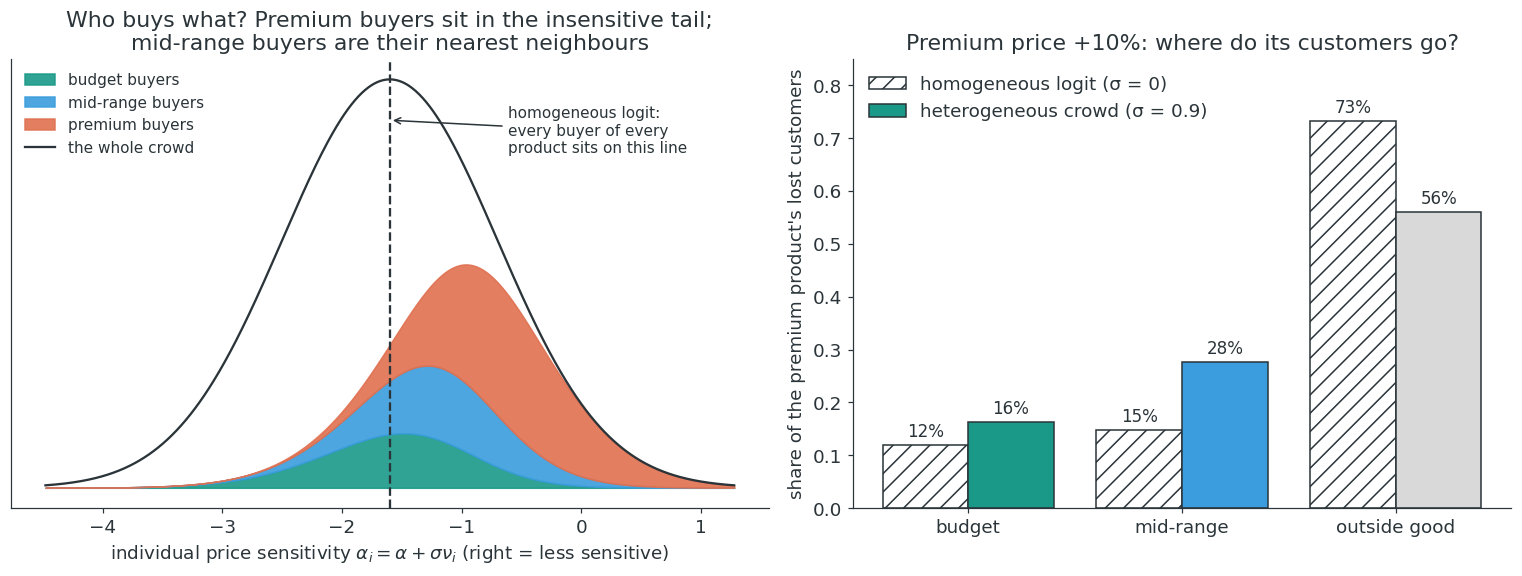

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axs[0]
# Decompose the crowd's density of price sensitivity by what each consumer buys.
# Each filled area integrates to that product's market share.
a_grid = np.linspace(alpha_m - 3.2 * sigma_m, alpha_m + 3.2 * sigma_m, 600)
nu_grid = (a_grid - alpha_m) / sigma_m
density = norm.pdf(nu_grid) / sigma_m
p_grid = crowd_probs(delta_mixed, sigma_m, nu_grid, price_m)
bottom = np.zeros_like(a_grid)
for j in range(3):
    ax.fill_between(a_grid, bottom, bottom + density * p_grid[:, j], color=PRODUCT_COLOURS[j],
                    alpha=0.9, label=f"{names[j]} buyers")
    bottom = bottom + density * p_grid[:, j]
ax.plot(a_grid, density, color=DARK, lw=1.5, label="the whole crowd")
ax.axvline(alpha_m, color=DARK, ls="--", lw=1.5)
ax.annotate("homogeneous logit:\nevery buyer of every\nproduct sits on this line", xy=(alpha_m, density.max() * 0.9),
            xytext=(alpha_m + 1.1 * sigma_m, density.max() * 0.82), fontsize=10, ha="left",
            arrowprops=dict(arrowstyle="->", color=DARK))
ax.set_xlabel(r"individual price sensitivity $\alpha_i = \alpha + \sigma\nu_i$ (right = less sensitive)")
ax.set_yticks([])
ax.set_title("Who buys what? Premium buyers sit in the insensitive tail;\nmid-range buyers are their nearest neighbours")
ax.legend(frameon=False, loc="upper left", fontsize=10)

ax = axs[1]
targets = ["budget", "mid-range", "outside good"]
pos = np.arange(len(targets))
b_logit = ax.bar(pos - 0.2, diversion_df.loc[targets, "logit diversion"], width=0.4, color="white",
                 edgecolor=DARK, hatch="//", label="homogeneous logit (σ = 0)")
b_crowd = ax.bar(pos + 0.2, diversion_df.loc[targets, "crowd diversion"], width=0.4,
                 color=[PRODUCT_COLOURS[0], PRODUCT_COLOURS[1], "#d9d9d9"], edgecolor=DARK,
                 label=f"heterogeneous crowd (σ = {sigma_m})")
for bars in (b_logit, b_crowd):
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in bars.datavalues], padding=3, fontsize=11)
ax.set_ylim(0, 0.85)
ax.set_xticks(pos, targets)
ax.set_ylabel("share of the premium product's lost customers")
ax.set_title("Premium price +10%: where do its customers go?")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{IMAGES}/same_shares_different_crowds.png", dpi=150, bbox_inches="tight")

Both models reproduce the observed shares exactly, yet they disagree about the counterfactual.

- **The homogeneous logit** sends the premium product's lost customers to each alternative in proportion to that alternative's share. This is the independence of irrelevant alternatives: 73% of them leave the category altogether.
- **The crowd** sends almost twice as many to the mid-range product (28% vs 15%). The left panel shows why. Splitting the crowd's price sensitivities by what each consumer buys, premium buyers sit furthest into the price-insensitive tail and mid-range buyers are their nearest neighbours. When premium gets dearer, its buyers move to the option that people like them already buy. In the logit, every buyer of every product has the same sensitivity, so there is no such structure to exploit.

Aggregate shares alone cannot tell these two stories apart. The crowd's composition is the thing the data has to be asked about.

## Layer 3: we don't know the crowd

Everything above assumed we knew $\alpha$ and $\sigma$. We don't. The data are aggregate shares, and many crowds are compatible with them. The Bayesian move is to treat the crowd's composition as a **latent variable**: put priors on $(\alpha, \sigma, \beta)$ and on the unobserved product appeal $\xi_{jm}$, and let the posterior say which crowds are plausible.

Then every quantity we care about is a third integral, over the posterior:

$$\mathbb{E}[\varepsilon_{jk} \mid \text{data}] = \int_\theta \underbrace{\int_\nu \underbrace{\int_\varepsilon (\cdots)\, dF(\varepsilon)}_{\text{logit, closed form}} dF(\nu)}_{\text{crowd, Halton}}\; p(\theta \mid \text{data})\, d\theta$$

The Halton crowd stays fixed; the posterior moves the parameters that turn standard-normal draws $\nu_r$ into actual price sensitivities $\alpha + \sigma \nu_r$.

### A Bayesian BLP from scratch

We simulate a panel with `generate_blp_panel` (40 markets, 3 products, 2 characteristics, heterogeneity on price only, exogenous prices so this first model needs no instruments) and write the model directly in PyMC.

In [11]:
df_simple, truth_simple = generate_blp_panel(
    T=40, J=3, K=2, L=2, true_alpha=-2.0, true_beta=np.array([0.8, 1.2]), sigma_alpha=0.6,
    sigma_beta=np.zeros(2), price_xi_corr=0.0, market_size=4_000, n_dgp_draws=5_000,
    random_seed=11, return_truth=True,
)
inside = df_simple[df_simple["product"] != "outside"].sort_values(["market", "product"])
outside = df_simple[df_simple["product"] == "outside"].sort_values("market")
products = sorted(inside["product"].unique())
M, J = outside.shape[0], len(products)
P = inside["price"].to_numpy().reshape(M, J)
X = inside[truth_simple["characteristic_cols"]].to_numpy().reshape(M, J, 2)
S = inside["share"].to_numpy().reshape(M, J)
S0 = outside["share"].to_numpy()
N = outside["n"].to_numpy()
print(f"{M} markets x {J} products; true alpha = {truth_simple['alpha']}, sigma = {truth_simple['sigma_alpha']}")

40 markets x 3 products; true alpha = -2.0, sigma = 0.6


In [12]:
R = 200
nu_crowd = halton_normal(R, 1, seed=SEED)[:, 0]  # the synthetic crowd: fixed data, not sampled
coords = {"market": np.arange(M), "product": products, "characteristic": ["x_0", "x_1"],
          "consumer": np.arange(R)}

with pm.Model(coords=coords) as blp_from_scratch:
    # Preferences of the average consumer, and the spread of the crowd
    alpha = pm.Normal("alpha", 0, 2)
    sigma = pm.HalfNormal("sigma", 1)
    beta = pm.Normal("beta", 0, 1, dims="characteristic")
    # Unobserved product appeal: a product effect plus market-level shocks
    xi_j = pm.Normal("xi_j", 0, 0.5, dims="product")
    sigma_xi = pm.HalfNormal("sigma_xi", 0.5)
    xi_raw = pm.Normal("xi_raw", 0, 1, dims=("market", "product"))
    xi = pm.Deterministic("xi", xi_j + sigma_xi * xi_raw, dims=("market", "product"))

    # Mean utility, then each synthetic consumer's deviation from it
    delta = alpha * P + (X * beta).sum(-1) + xi  # (M, J)
    crowd = pm.Data("crowd", nu_crowd, dims="consumer")
    utility = delta[:, :, None] + sigma * crowd[None, None, :] * P[:, :, None]  # (M, J, R)

    # Integrate the logit over the crowd: average every consumer's choice probabilities
    u_full = pt.concatenate([utility, pt.zeros((M, 1, R))], axis=1)  # outside good last
    probs = pt.special.softmax(u_full, axis=1)
    shares = probs.mean(axis=-1)  # (M, J + 1): the crowd's average choice

    # Berry (1994) log-share-ratio likelihood with multinomial sampling noise
    log_ratio = pt.log(shares[:, :J]) - pt.log(shares[:, J])[:, None]
    noise = np.sqrt(1 / (N[:, None] * S) + 1 / (N * S0)[:, None])
    pm.Normal("log_share_ratio", mu=log_ratio, sigma=noise,
              observed=np.log(S) - np.log(S0)[:, None], dims=("market", "product"))

    t0 = time.perf_counter()
    idata_scratch = pm.sample(**FIT_KWARGS)
    scratch_seconds = time.perf_counter() - t0

print(f"fit time: {scratch_seconds:.0f}s for 4 chains x 1000 draws")

print("divergences:", int(idata_scratch["sample_stats"]["diverging"].sum()))
az.summary(idata_scratch, var_names=["alpha", "sigma", "beta", "sigma_xi"], kind="stats")

NUTS[nutpie]: [alpha, sigma, beta, xi_j, sigma_xi, xi_raw]


fit time: 21s for 4 chains x 1000 draws
divergences: 0


,mean,sd,eti89_lb,eti89_ub
alpha,-2.1,0.067,-2.2,-2
sigma,0.68,0.039,0.61,0.74
beta[x_0],0.79,0.063,0.69,0.89
beta[x_1],1.2,0.031,1.1,1.2
sigma_xi,0.26,0.022,0.23,0.29


,truth,mean,hdi_lo,hdi_hi
price coefficient $\alpha$,-2.0,-2.105,-2.242,-1.988
crowd spread $\sigma$,0.6,0.677,0.604,0.750
$\beta_{x_0}$,0.8,0.790,0.675,0.915
$\beta_{x_1}$,1.2,1.172,1.114,1.230


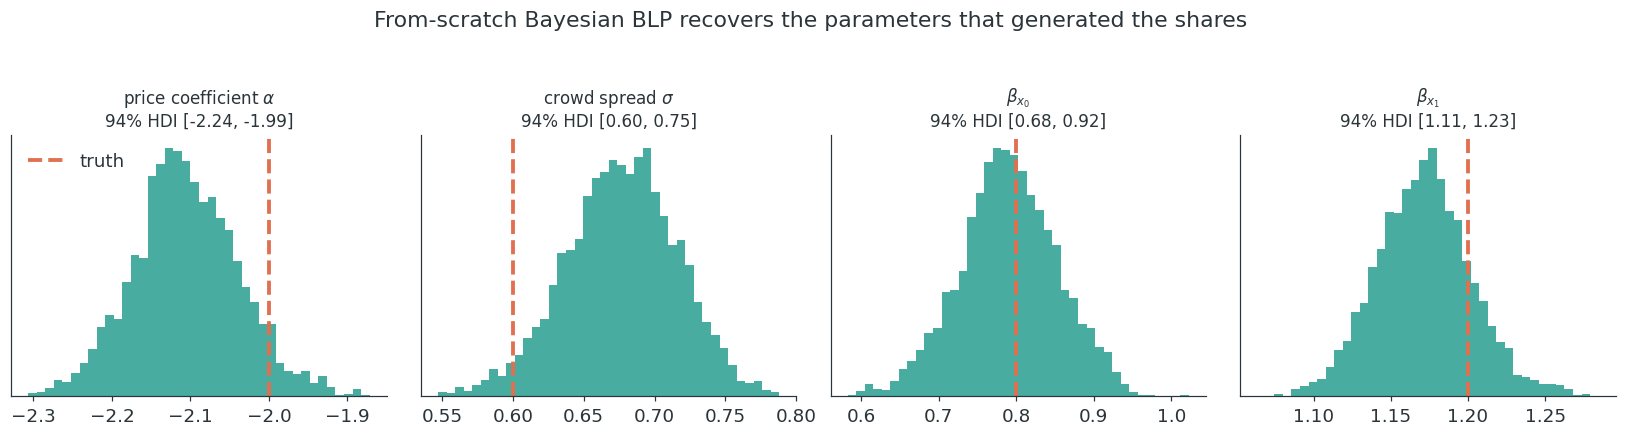

In [13]:
post = idata_scratch["posterior"]
recovery = {
    r"price coefficient $\alpha$": (post["alpha"].values.ravel(), truth_simple["alpha"]),
    r"crowd spread $\sigma$": (post["sigma"].values.ravel(), truth_simple["sigma_alpha"]),
    r"$\beta_{x_0}$": (post["beta"].sel(characteristic="x_0").values.ravel(), truth_simple["beta"][0]),
    r"$\beta_{x_1}$": (post["beta"].sel(characteristic="x_1").values.ravel(), truth_simple["beta"][1]),
}
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (title, (draws, true)) in zip(axs, recovery.items()):
    ax.hist(draws, bins=40, color=TEAL, alpha=0.8, density=True)
    ax.axvline(true, color=CORAL, lw=2.5, ls="--", label="truth")
    lo, hi = az.hdi(draws, prob=0.94)
    ax.set_title(f"{title}\n94% HDI [{lo:.2f}, {hi:.2f}]", fontsize=11)
    ax.set_yticks([])
axs[0].legend(frameon=False)
fig.suptitle("From-scratch Bayesian BLP recovers the parameters that generated the shares", y=1.04)
fig.tight_layout()
fig.savefig(f"{IMAGES}/scratch_recovery.png", dpi=150, bbox_inches="tight")

recovery_table = pd.DataFrame(
    {name: {"truth": true, "mean": draws.mean(), "hdi_lo": az.hdi(draws, prob=0.94)[0],
            "hdi_hi": az.hdi(draws, prob=0.94)[1]} for name, (draws, true) in recovery.items()}
).T
recovery_table.round(3)

The posterior concentrates near the truth for every parameter. The crowd spread $\sigma$ is the hardest to pin down: its 94% interval runs from 0.60 to 0.75 and narrowly misses the true 0.6, so the model slightly overstates the crowd's heterogeneity. Heterogeneity is identified from how shares *bend* across markets with different prices, which is a second-order signal in aggregate data.

### Every posterior draw is a different crowd

Each posterior draw of $(\alpha, \sigma)$ turns the same Halton points into a different population of price sensitivities $\alpha + \sigma \nu_r$. The posterior is a distribution over crowds.

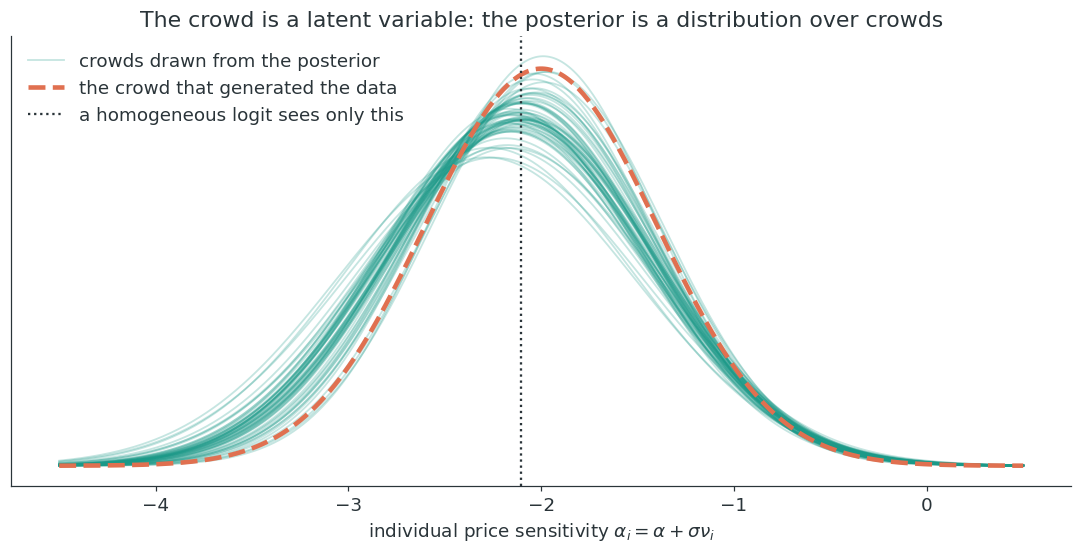

In [14]:
grid = np.linspace(-4.5, 0.5, 400)
a_draws = post["alpha"].values.ravel()
s_draws = post["sigma"].values.ravel()
pick = rng.choice(a_draws.size, size=60, replace=False)

fig, ax = plt.subplots(figsize=(10, 5.2))
for k, idx in enumerate(pick):
    ax.plot(grid, norm.pdf(grid, a_draws[idx], s_draws[idx]), color=TEAL, alpha=0.25, lw=1.2,
            label="crowds drawn from the posterior" if k == 0 else None)
ax.plot(grid, norm.pdf(grid, truth_simple["alpha"], truth_simple["sigma_alpha"]), color=CORAL, lw=3,
        ls="--", label="the crowd that generated the data")
ax.axvline(a_draws.mean(), color=DARK, lw=1.5, ls=":", label="a homogeneous logit sees only this")
ax.set_xlabel(r"individual price sensitivity $\alpha_i = \alpha + \sigma \nu_i$")
ax.set_yticks([])
ax.set_title("The crowd is a latent variable: the posterior is a distribution over crowds")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(f"{IMAGES}/posterior_crowds.png", dpi=150, bbox_inches="tight")

### De Finetti's crowd

There is a deeper reason BLP is such a natural Bayesian case study. De Finetti's (1937) representation theorem says that if we regard a sequence of observations as **exchangeable** (their order carries no information), we may write their joint distribution as a mixture of independent draws governed by a latent parameter:

$$p(y_1, \dots, y_n) = \int \prod_{i=1}^{n} p(y_i \mid \theta)\, \pi(d\theta)$$

Shoppers are not exchangeable outright: they face different prices and have different tastes. They are **conditionally** exchangeable. Given the market $m$ (its prices, characteristics and unmeasured appeal $\xi$) and a taste profile $\nu$, two shoppers are interchangeable, and each choice is a logit draw. Taste profiles are latent, so we integrate them over the crowd $F(\nu \mid \theta)$, and the crowd's composition $\theta$ carries the prior:

$$p(y_1, \dots, y_n \mid m) = \int \prod_{i=1}^{n} \int p(y_i \mid m, \nu)\, dF(\nu \mid \theta)\; \pi(d\theta)$$

The nesting of the integrals is the nesting of the exchangeability judgements: exchangeable given the taste profile (the logit), the taste profile integrated over the crowd (Layer 2), and the crowd's composition $\theta$ as the de Finetti parameter (Layer 3).

As Bernardo (1996) puts it, the theorem "proves that if observations are judged to be exchangeable, then they must indeed be a random sample from some model and there must exist a prior probability distribution over the parameter of the model". But it is an existence result: "it generally does not specify the model, and it never specifies the required prior distribution."

That is where BLP earns its place as a case study. The economics supplies the structure the theorem leaves open: a utility model, a Halton crowd, product appeal shared across markets, a price equation, and (in `BayesianBLP`) a hierarchy across regions, which is how Bernardo's *partial* exchangeability across related markets is expressed. This richly structured prior on the mixing distribution is why aggregate shares, which by themselves say very little, can still identify a crowd.

The third integral in action: the own-price elasticity of each product, averaged over markets, computed for every posterior draw. For a mixed logit,

$$\varepsilon_{jj} = \frac{p_j}{s_j} \cdot \frac{1}{R} \sum_r \alpha_r\, s_{jr} (1 - s_{jr})$$

where the inner average is over the synthetic crowd. Repeating it for every posterior draw gives a full distribution, rather than a point estimate with a delta-method standard error.

In [15]:
def own_elasticities(alpha, sigma, beta, xi):
    # Market-averaged own-price elasticity for each product, one posterior draw.
    delta = alpha * P + (X * beta).sum(-1) + xi
    alpha_r = alpha + sigma * nu_crowd  # (R,)
    s_r = logit_shares(delta[:, None, :] + sigma * nu_crowd[None, :, None] * P[:, None, :])[..., :J]  # (M, R, J)
    s = s_r.mean(axis=1)
    ds = (alpha_r[None, :, None] * s_r * (1 - s_r)).mean(axis=1)
    return (P / s * ds).mean(axis=0)


stacked = az.extract(idata_scratch, num_samples=1000, random_seed=SEED)
eps_draws = np.array([
    own_elasticities(float(stacked["alpha"][i]), float(stacked["sigma"][i]),
                     stacked["beta"].values[:, i], stacked["xi"].values[:, :, i])
    for i in range(stacked.sizes["sample"])
])
eps_summary = pd.DataFrame({
    "mean": eps_draws.mean(0),
    "hdi_lo": [az.hdi(eps_draws[:, j], prob=0.94)[0] for j in range(J)],
    "hdi_hi": [az.hdi(eps_draws[:, j], prob=0.94)[1] for j in range(J)],
}, index=products)
eps_summary.round(2)

,mean,hdi_lo,hdi_hi
prod_0,-2.77,-2.90,-2.64
prod_1,-2.83,-2.99,-2.67
prod_2,-2.10,-2.18,-2.02


## The unmeasured appeal: endogenous prices with `BayesianBLP`

The from-scratch model hid a problem. Firms set prices knowing their product's unobserved appeal $\xi_{jm}$: popular products get priced up. Then price and $\xi$ are correlated, and a model that ignores this mistakes "expensive *because* popular" for "consumers don't mind the price". The estimated price coefficient is biased towards zero.

The `BayesianBLP` class in PyMC-Marketing adds a first-stage price equation with instruments $z_{jm}$ (cost shifters, rival characteristics) and models $\xi$ jointly with the price residual. We simulate a panel with endogenous prices (`price_xi_corr=0.6`) and heterogeneity on price and both characteristics, then fit it with and without instruments.

In [16]:
df_endog, truth_endog = generate_blp_panel(
    T=40, J=3, K=2, L=2, true_alpha=-2.0, true_beta=np.array([0.8, 1.2]), sigma_alpha=0.5,
    sigma_beta=np.array([0.4, 0.5]), instrument_strength=0.7, price_xi_corr=0.6,
    market_size=4_000, n_dgp_draws=3_000, random_seed=42, return_truth=True,
)
blp_kwargs = dict(characteristics=truth_endog["characteristic_cols"], random_coef_on=["price", "x_0", "x_1"],
                  n_mc_draws=200, random_seed=0)

model_iv = BayesianBLP(market_data=df_endog, instruments=truth_endog["instrument_cols"], **blp_kwargs)
model_iv.fit(**FIT_KWARGS)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    model_noiv = BayesianBLP(market_data=df_endog, instruments=None, **blp_kwargs)
    model_noiv.fit(**FIT_KWARGS)

for name, m in [("IV", model_iv), ("no IV", model_noiv)]:
    print(f"{name:6s} divergences: {int(m.idata['sample_stats']['diverging'].sum())}")
az.summary(model_iv.idata, var_names=["alpha_r", "sigma_random", "rho_price_xi"], kind="stats")

NUTS[nutpie]: [alpha, beta, sigma_xi_j, xi_j_raw, sigma_eta, pi_0, pi_z, gamma_xi_eta, omega_xi, xi_tilde_raw, sigma_random]
NUTS[nutpie]: [alpha, beta, sigma_xi_j, xi_j_raw, sigma_xi_free, xi_tilde_raw, sigma_random]


IV     divergences: 0
no IV  divergences: 0


,mean,sd,eti89_lb,eti89_ub
alpha_r[all],-2,0.071,-2.1,-1.9
sigma_random[price],0.53,0.042,0.47,0.6
sigma_random[x_0],0.49,0.25,0.074,0.86
sigma_random[x_1],0.46,0.092,0.31,0.6
rho_price_xi,0.51,0.12,0.31,0.68


,mean,hdi_lo,hdi_hi,truth
with instruments,-1.988,-2.121,-1.860,-2.0
without instruments,-1.905,-2.040,-1.778,-2.0


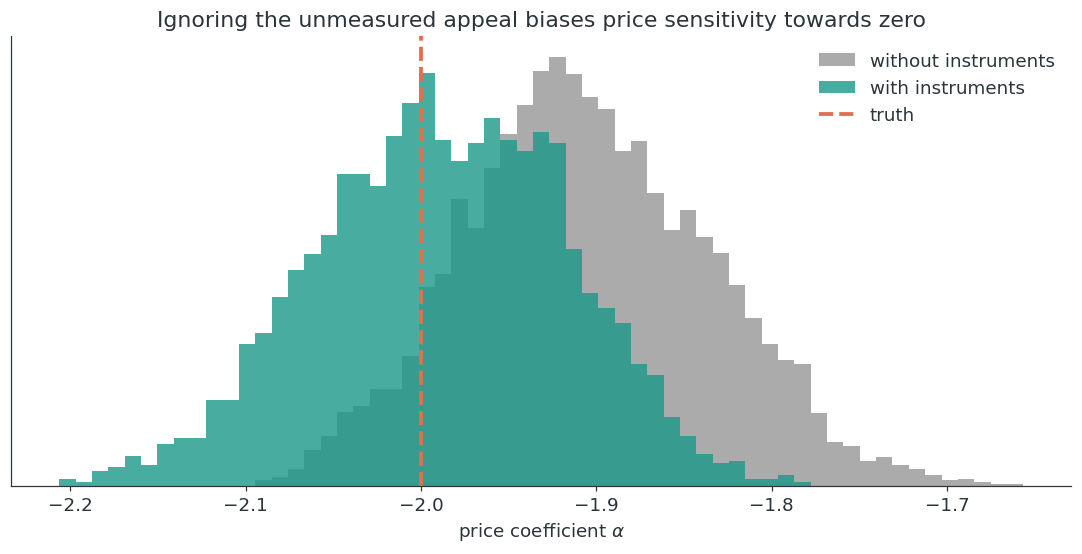

In [17]:
alpha_iv = model_iv.idata["posterior"]["alpha_r"].values.ravel()
alpha_noiv = model_noiv.idata["posterior"]["alpha_r"].values.ravel()
iv_table = pd.DataFrame({
    "with instruments": [alpha_iv.mean(), *az.hdi(alpha_iv, prob=0.94)],
    "without instruments": [alpha_noiv.mean(), *az.hdi(alpha_noiv, prob=0.94)],
}, index=["mean", "hdi_lo", "hdi_hi"]).T
iv_table["truth"] = truth_endog["alpha"]

fig, ax = plt.subplots(figsize=(10, 5.2))
bins = np.linspace(min(alpha_iv.min(), alpha_noiv.min()), max(alpha_iv.max(), alpha_noiv.max()), 60)
ax.hist(alpha_noiv, bins=bins, color=GREY, alpha=0.7, density=True, label="without instruments")
ax.hist(alpha_iv, bins=bins, color=TEAL, alpha=0.8, density=True, label="with instruments")
ax.axvline(truth_endog["alpha"], color=CORAL, lw=2.5, ls="--", label="truth")
ax.set_xlabel(r"price coefficient $\alpha$")
ax.set_yticks([])
ax.set_title("Ignoring the unmeasured appeal biases price sensitivity towards zero")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(f"{IMAGES}/iv_vs_noiv.png", dpi=150, bbox_inches="tight")
iv_table.round(3)

## Nevo's cereal panel

Now the benchmark: the cereal data from Nevo's (2000) *Practitioner's Guide*, with 24 brands across 47 cities and 2 quarters, prices, two characteristics (sugar, mushy) and Hausman-style instruments (the brand's price in other markets). Following the PyMC-Marketing example notebook, we:

- take 8 cities × 2 quarters (16 markets) so the fit takes minutes;
- rescale price to cents;
- synthesise the outside good as one minus the inside shares;
- set the market size to a placeholder $n = 1{,}000$.

Two caveats carry through to every number below. Nevo's data are *simulated* to resemble the cereal market rather than real scanner data, and the market size is a placeholder that scales interval widths.

In [18]:
raw = pd.read_csv("data_nevo.csv", decimal=",")
raw["period"] = raw["year"].astype(int) * 4 + raw["quarter"].astype(int)
raw["region"] = "c" + raw["city"].astype(str)
raw["market"] = raw["region"] + "_" + raw["period"].astype(str)
firm_names = {1: "Kelloggs", 2: "GenMills", 3: "Post", 4: "Quaker", 6: "Ralston"}
raw["product"] = raw["firm"].map(firm_names) + "_" + raw["brand"].astype(int).astype(str)

INSTRUMENTS = [f"z{i}" for i in range(6, 11)]
keep_cities = sorted(raw["city"].unique())[:8]
nevo_inside = raw[raw["city"].isin(keep_cities)].copy()
nevo_inside["price"] = nevo_inside["price"] * 100.0  # cents
outside_share = 1.0 - nevo_inside.groupby("market")["share"].sum()
meta = nevo_inside.drop_duplicates("market").set_index("market")[["region", "period"]]
nevo_outside = pd.DataFrame({
    "market": outside_share.index, "product": "outside", "share": outside_share.values,
    "price": 0.0, "sugar": 0.0, "mushy": 0.0, **{c: 0.0 for c in INSTRUMENTS},
})
nevo_outside["region"] = meta.reindex(nevo_outside["market"])["region"].values
nevo_outside["period"] = meta.reindex(nevo_outside["market"])["period"].values
nevo_inside["n"] = 1000
nevo_outside["n"] = 1000
nevo = pd.concat([nevo_inside, nevo_outside], ignore_index=True, sort=False)
print(f"{nevo['market'].nunique()} markets x {nevo['product'].nunique() - 1} brands + outside good")

16 markets x 24 brands + outside good


In [19]:
from pymc_extras.prior import Prior

model_nevo = BayesianBLP(
    market_data=nevo, characteristics=["sugar", "mushy"], instruments=INSTRUMENTS,
    region_col="region", time_col="period", random_coef_on=["price", "sugar", "mushy"],
    n_mc_draws=200, hierarchical_parameterisation="noncentered", random_seed=0,
    model_config={"sigma_xi": Prior("HalfNormal", sigma=0.5), "sigma_xi_j": Prior("HalfNormal", sigma=0.25),
                  "alpha": Prior("Normal", mu=0.0, sigma=3.0)},
)
t0 = time.perf_counter()
model_nevo.fit(**{**FIT_KWARGS, "draws": 2000, "init": "adapt_full"})
nevo_seconds = time.perf_counter() - t0
print(f"fit time: {nevo_seconds / 60:.1f} min; divergences:", int(model_nevo.idata["sample_stats"]["diverging"].sum()))
az.summary(model_nevo.idata, var_names=["alpha_pop", "sigma_random", "rho_price_xi"], kind="stats")

NUTS[nutpie]: [alpha_pop, beta_pop, tau_alpha, tau_beta, alpha_r_raw, beta_r_raw, sigma_xi_j, xi_j_raw, sigma_eta, pi_0, pi_z, gamma_xi_eta, omega_xi, xi_tilde_raw, sigma_random]


fit time: 3.3 min; divergences: 0


,mean,sd,eti89_lb,eti89_ub
alpha_pop,-0.33,0.034,-0.38,-0.28
sigma_random[price],0.15,0.028,0.11,0.19
sigma_random[sugar],0.032,0.024,0.0027,0.078
sigma_random[mushy],0.29,0.21,0.028,0.69
rho_price_xi,0.33,0.13,0.11,0.52


median own elasticity -2.78; range [-2.94, -2.43]


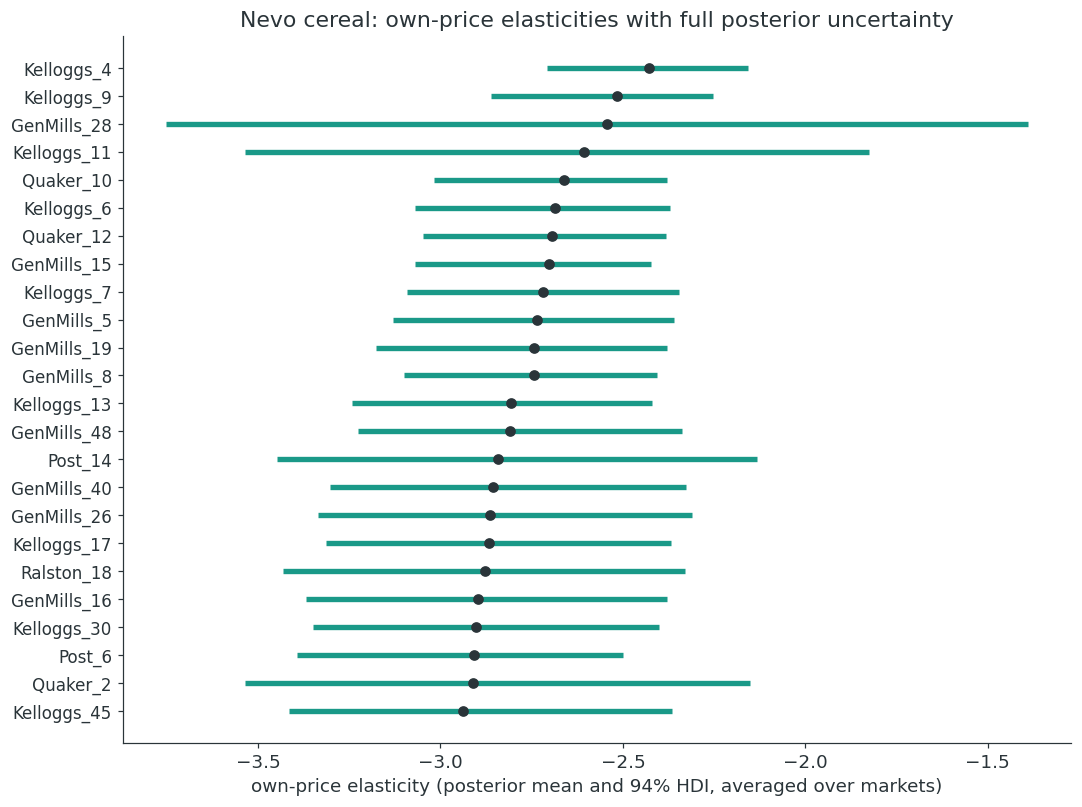

In [20]:
elast_samples = model_nevo.elasticities(at="samples", n_samples=400)
own = np.stack([elast_samples.values[:, :, j, j].mean(axis=1) for j in range(model_nevo._J)], axis=1)
own_df = pd.DataFrame({
    "mean": own.mean(0),
    "hdi_lo": [az.hdi(own[:, j], prob=0.94)[0] for j in range(own.shape[1])],
    "hdi_hi": [az.hdi(own[:, j], prob=0.94)[1] for j in range(own.shape[1])],
}, index=model_nevo._inside_products).sort_values("mean")

fig, ax = plt.subplots(figsize=(10, 7.5))
ypos = np.arange(len(own_df))
ax.hlines(ypos, own_df["hdi_lo"], own_df["hdi_hi"], color=TEAL, lw=3.5)
ax.plot(own_df["mean"], ypos, "o", color=DARK, ms=6)
ax.set_yticks(ypos, own_df.index, fontsize=11)
ax.set_xlabel("own-price elasticity (posterior mean and 94% HDI, averaged over markets)")
ax.set_title("Nevo cereal: own-price elasticities with full posterior uncertainty")
fig.tight_layout()
fig.savefig(f"{IMAGES}/nevo_elasticities.png", dpi=150, bbox_inches="tight")
print(f"median own elasticity {own_df['mean'].median():.2f}; range [{own_df['mean'].min():.2f}, {own_df['mean'].max():.2f}]")

### The opening question: a competitor cuts its price by 10%

Take the Kellogg's brand with the largest average share as "our" cereal and the General Mills brand with the largest average share as the competitor. `counterfactual_shares` holds each market's posterior $\xi$ fixed and re-evaluates the share integral over the synthetic crowd at the new prices, once per posterior draw.

In [21]:
mean_share = nevo_inside.groupby("product")["share"].mean()
ours = mean_share[mean_share.index.str.startswith("Kelloggs")].idxmax()
rival = mean_share[mean_share.index.str.startswith("GenMills")].idxmax()
j_ours, j_rival = model_nevo._inside_products.index(ours), model_nevo._inside_products.index(rival)

def competitor_cut(model, n_samples=1000):
    # Posterior draws of the counterfactual quantities for a 10% price cut by the rival.
    base = model.counterfactual_shares(price_change=None, n_samples=n_samples)
    cut = model.counterfactual_shares(price_change={rival: -0.10}, n_samples=n_samples)
    s_base = base["s_inside"].mean("market")  # (sample, product)
    s_cut = cut["s_inside"].mean("market")
    gain = s_cut[:, j_rival] - s_base[:, j_rival]
    return {
        "pct_ours": (100 * (s_cut[:, j_ours] - s_base[:, j_ours]) / s_base[:, j_ours]).values,
        "pct_rival": (100 * (s_cut[:, j_rival] - s_base[:, j_rival]) / s_base[:, j_rival]).values,
        "from_ours": (-(s_cut[:, j_ours] - s_base[:, j_ours]) / gain).values,
        "from_outside": (-(cut["s_outside"].mean("market") - base["s_outside"].mean("market")) / gain).values,
    }


crowd_cf = competitor_cut(model_nevo)
pct_ours, pct_rival = crowd_cf["pct_ours"], crowd_cf["pct_rival"]
from_ours, from_outside = crowd_cf["from_ours"], crowd_cf["from_outside"]

cf_table = pd.DataFrame({
    f"% change in {ours} share": [float(pct_ours.mean()), *az.hdi(pct_ours, prob=0.94)],
    f"% change in {rival} share": [float(pct_rival.mean()), *az.hdi(pct_rival, prob=0.94)],
    f"share of {rival}'s gain taken from {ours}": [float(from_ours.mean()), *az.hdi(from_ours, prob=0.94)],
    f"share of {rival}'s gain from the outside good": [float(from_outside.mean()), *az.hdi(from_outside, prob=0.94)],
}, index=["mean", "hdi_lo", "hdi_hi"]).T
print(f"our brand: {ours} (mean share {mean_share[ours]:.3f}); competitor: {rival} (mean share {mean_share[rival]:.3f})")
cf_table.round(3)

our brand: Kelloggs_11 (mean share 0.061); competitor: GenMills_19 (mean share 0.035)


,mean,hdi_lo,hdi_hi
% change in Kelloggs_11 share,-0.693,-0.882,-0.503
% change in GenMills_19 share,29.125,25.223,32.682
share of GenMills_19's gain taken from Kelloggs_11,0.041,0.032,0.049
share of GenMills_19's gain from the outside good,0.547,0.515,0.580


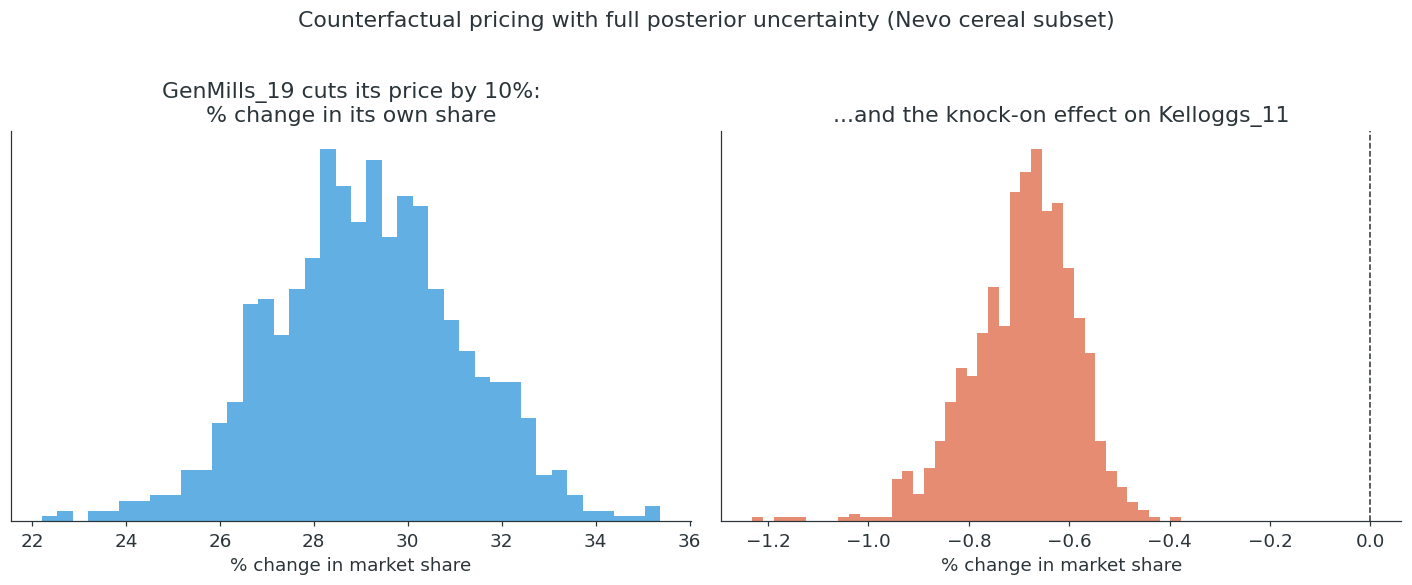

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axs[0]
ax.hist(pct_rival, bins=40, color=BLUE, alpha=0.8, density=True)
ax.set_title(f"{rival} cuts its price by 10%:\n% change in its own share")
ax.set_xlabel("% change in market share"); ax.set_yticks([])
ax = axs[1]
ax.hist(pct_ours, bins=40, color=CORAL, alpha=0.8, density=True)
ax.axvline(0, color=DARK, lw=1, ls="--")
ax.set_title(f"...and the knock-on effect on {ours}")
ax.set_xlabel("% change in market share"); ax.set_yticks([])
fig.suptitle("Counterfactual pricing with full posterior uncertainty (Nevo cereal subset)", y=1.02)
fig.tight_layout()
fig.savefig(f"{IMAGES}/nevo_counterfactual.png", dpi=150, bbox_inches="tight")

### Did the crowd matter here? The same question for a homogeneous logit

The synthetic example showed that a homogeneous logit and a heterogeneous crowd can fit the same shares and still disagree about counterfactuals. Whether they disagree on *this* data is an empirical question. We refit the Nevo panel with `random_coef_on=[]`: the same instruments, priors, hierarchy and product appeal $\xi$, but every consumer has the same tastes. Then we ask the same counterfactual question of both models.

In [23]:
model_logit = BayesianBLP(
    market_data=nevo, characteristics=["sugar", "mushy"], instruments=INSTRUMENTS,
    region_col="region", time_col="period", random_coef_on=[],  # homogeneous logit
    n_mc_draws=1, hierarchical_parameterisation="noncentered", random_seed=0,
    model_config={"sigma_xi": Prior("HalfNormal", sigma=0.5), "sigma_xi_j": Prior("HalfNormal", sigma=0.25),
                  "alpha": Prior("Normal", mu=0.0, sigma=3.0)},
)
t0 = time.perf_counter()
model_logit.fit(**{**FIT_KWARGS, "draws": 2000, "init": "adapt_full"})
print(f"fit time: {(time.perf_counter() - t0) / 60:.1f} min; divergences:",
      int(model_logit.idata["sample_stats"]["diverging"].sum()))

logit_cf = competitor_cut(model_logit)
rows = {}
for label, key in [(f"% change in {rival} share", "pct_rival"), (f"% change in {ours} share", "pct_ours"),
                   (f"share of {rival}'s gain from the outside good", "from_outside"),
                   (f"share of {rival}'s gain taken from {ours}", "from_ours")]:
    for model_name, cf in [("logit", logit_cf), ("crowd", crowd_cf)]:
        lo, hi = az.hdi(cf[key], prob=0.94)
        rows[(label, model_name)] = {"mean": cf[key].mean(), "hdi_lo": lo, "hdi_hi": hi}
logit_vs_crowd = pd.DataFrame(rows).T
logit_vs_crowd.round(3)

NUTS[nutpie]: [alpha_pop, beta_pop, tau_alpha, tau_beta, alpha_r_raw, beta_r_raw, sigma_xi_j, xi_j_raw, sigma_eta, pi_0, pi_z, gamma_xi_eta, omega_xi, xi_tilde_raw]


fit time: 0.4 min; divergences: 0


mean  hdi_lo  \
% change in GenMills_19 share                      logit  30.542  26.788   
                                                   crowd  29.125  25.223   
% change in Kelloggs_11 share                      logit  -0.729  -0.875   
                                                   crowd  -0.693  -0.882   
share of GenMills_19's gain from the outside good  logit   0.577   0.566   
                                                   crowd   0.547   0.515   
share of GenMills_19's gain taken from Kelloggs_11 logit   0.041   0.034   
                                                   crowd   0.041   0.032   

                                                          hdi_hi  
% change in GenMills_19 share                      logit  34.273  
                                                   crowd  32.682  
% change in Kelloggs_11 share                      logit  -0.570  
                                                   crowd  -0.503  
share of GenMills_19's gain from the outside good  logit   0.589  
                                                   crowd   0.580  
share of GenMills_19's gain taken from Kelloggs_11 logit   0.047  
                                                   crowd   0.049

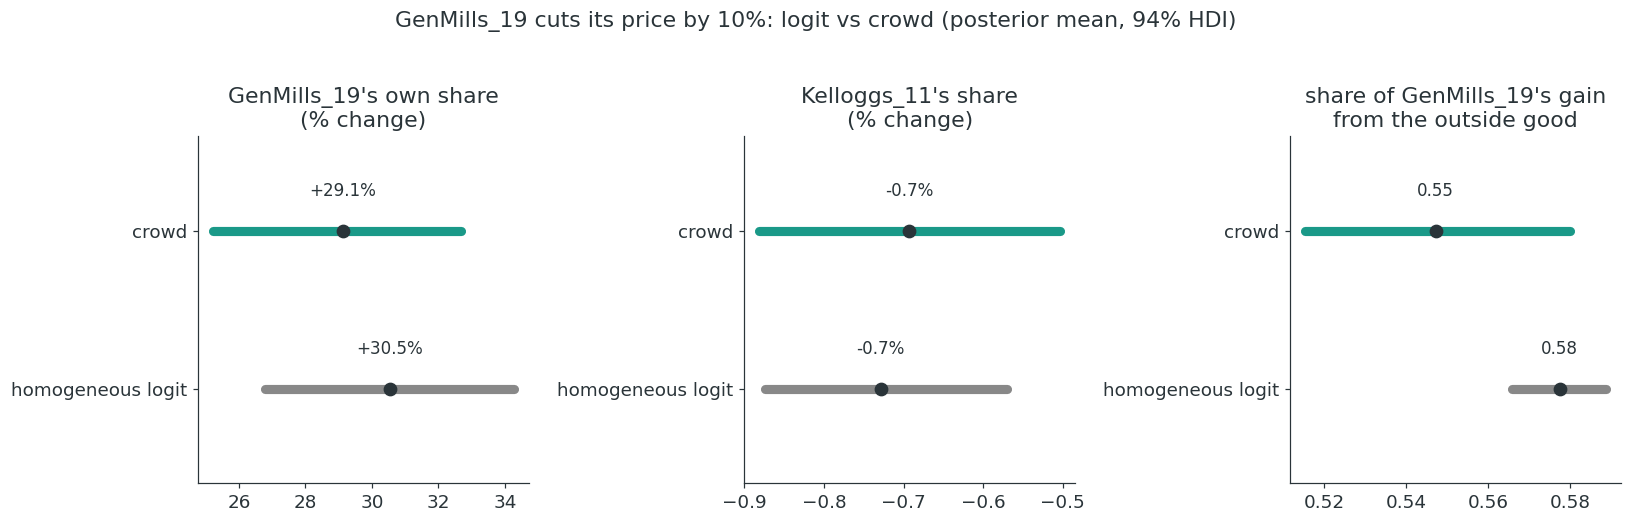

In [24]:
panels = [("pct_rival", f"{rival}'s own share\n(% change)"),
          ("pct_ours", f"{ours}'s share\n(% change)"),
          ("from_outside", f"share of {rival}'s gain\nfrom the outside good")]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (key, title) in zip(axs, panels):
    for k, (name, cf, colour) in enumerate([("homogeneous logit", logit_cf, GREY), ("crowd", crowd_cf, TEAL)]):
        lo, hi = az.hdi(cf[key], prob=0.94)
        ax.plot([lo, hi], [k, k], color=colour, lw=6, solid_capstyle="round")
        ax.plot(cf[key].mean(), k, "o", color=DARK, ms=8)
        ax.text(cf[key].mean(), k + 0.22, f"{cf[key].mean():.2f}" if key == "from_outside" else f"{cf[key].mean():+.1f}%",
                ha="center", fontsize=11)
    ax.set_yticks([0, 1], ["homogeneous logit", "crowd"])
    ax.set_ylim(-0.6, 1.6)
    ax.set_title(title)
fig.suptitle(f"{rival} cuts its price by 10%: logit vs crowd (posterior mean, 94% HDI)", y=1.03)
fig.tight_layout()
fig.savefig(f"{IMAGES}/nevo_logit_vs_crowd.png", dpi=150, bbox_inches="tight")

- **Elasticities.** Own-price elasticities sit between about −2.4 and −2.9 (median −2.78), each with a 94% interval rather than a delta-method standard error. A few brands, including Kelloggs_11, have wide intervals: the data pin their demand down poorly.
- **The counterfactual.** When GenMills_19 cuts its price by 10%, its share rises by about 29%. Kelloggs_11, the largest Kellogg's brand in this subset, loses about 0.7% of its share. Only about 4% of the General Mills gain comes from Kelloggs_11; more than half comes from consumers who would otherwise have bought no cereal in this category at all.
- **Did the crowd matter?** Not much, for this question. The homogeneous logit gives almost the same answers: +30.5% for GenMills_19, −0.73% for Kelloggs_11, and 58% of the gain from the outside good (crowd: 55%), with overlapping intervals. With two brands at similar prices and a modest spread of price sensitivity, the logit's substitution pattern is close enough. That is a result, not a failure: the synthetic market earlier showed a case where the crowd changed the counterfactual completely, and having the crowd in the model is what lets the data tell us which situation we are in.

Brand identities in Nevo's data are coded, so Kelloggs_11 stands in for the Corn Flakes of the opening question. The data are simulated to resemble the cereal market, and the market size is a placeholder, so treat the magnitudes as an illustration of the workflow rather than as findings about cereal.

## Summary

- **Integration is averaging.** Low-discrepancy (Halton) crowds average far more accurately than random ones of the same size.
- **Layer 1.** The logit is an integral over Gumbel shocks with a closed form.
- **Layer 2.** A market share is that logit integrated over a crowd of tastes, approximated by a fixed population of synthetic consumers. The crowd is not its average member: identical observed shares can hide different crowds, and different crowds give different counterfactuals.
- **Layer 3.** We never observe the crowd. Putting priors on the parameters that shape it, and on the unmeasured product appeal $\xi$, turns the crowd into a latent variable. Every elasticity and counterfactual then becomes an average over the posterior: an integral over crowds.
- **No inversion.** The classical contraction mapping and GMM disappear. Their roles are taken by latent variables, priors and a joint model of price and appeal, and PyMC-Marketing's `BayesianBLP` packages that model.

### References

- Berry, S. (1994). Estimating Discrete-Choice Models of Product Differentiation. *RAND Journal of Economics*, 25(2), 242–262.
- Berry, S., Levinsohn, J., & Pakes, A. (1995). Automobile Prices in Market Equilibrium. *Econometrica*, 63(4), 841–890.
- de Finetti, B. (1937). La prévision: ses lois logiques, ses sources subjectives. *Annales de l'Institut Henri Poincaré*, 7(1), 1–68.
- Bernardo, J. M. (1996). The Concept of Exchangeability and its Applications. *Far East Journal of Mathematical Sciences*, Special Volume, 111–121.
- Dubé, J.-P., Fox, J. T., & Su, C.-L. (2012). Improving the Numerical Performance of Static and Dynamic Aggregate Discrete Choice Random Coefficients Demand Estimation. *Econometrica*, 80(5), 2231–2267.
- Jiang, R., Manchanda, P., & Rossi, P. E. (2009). Bayesian Analysis of Random Coefficient Logit Models Using Aggregate Data. *Journal of Econometrics*, 149(2), 136–148.
- McFadden, D. (1974). Conditional Logit Analysis of Qualitative Choice Behavior. In P. Zarembka (ed.), *Frontiers in Econometrics*.
- Nevo, A. (2000). A Practitioner's Guide to Estimation of Random-Coefficients Logit Models of Demand. *Journal of Economics & Management Strategy*, 9(4), 513–548.
- Train, K. (2009). *Discrete Choice Methods with Simulation* (2nd ed.). Cambridge University Press.

In [25]:
import sys, pytensor, nutpie
print(f"Python {sys.version.split()[0]} | PyMC {pm.__version__} | PyTensor {pytensor.__version__} | "
      f"PyMC-Marketing {pymc_marketing.__version__} | ArviZ {az.__version__} | nutpie {nutpie.__version__}")

Python 3.13.14 | PyMC 6.3.2 | PyTensor 3.3.3 | PyMC-Marketing 1.2.0 | ArviZ 1.3.0 | nutpie 0.16.11
